In [ ]:
# ============================================================
# 01_host_eda.ipynb — 환경 설정 (config.py 자동 로드)
# ============================================================
import sys
from pathlib import Path

# 프로젝트 루트를 sys.path에 추가 (실행 위치 무관)
for _p in [Path.cwd(), Path.cwd().parent]:
    if (_p / 'config.py').exists():
        sys.path.insert(0, str(_p))
        break

from config import *  # 모든 상수·경로·KPI·시각화 설정·헬퍼 함수 일괄 적용

# ── 데이터 로드 (호스트 EDA용)
df    = load_raw()                   # 전체 32,061건
df_ao = load_raw(active_only=True)   # Active+Operating 14,399건

print(f"✅ 데이터 로드: {len(df):,}건 (Active+Oper: {len(df_ao):,}건)")
print(f"   슈퍼호스트 RevPAR 프리미엄: +{KPI_SUPERHOST_PREMIUM*100:.1f}%")
print(f"   (₩{KPI_SUPERHOST_REVPAR_MEDIAN:,.0f} vs ₩{KPI_NON_SH_REVPAR_MEDIAN:,.0f})")

# 🏠 호스트 관점 EDA — 숙소 특성별 RevPAR 분석

**분석 목적:** 호스트가 통제 가능한 요소들이 RevPAR에 미치는 영향을 탐색합니다.

**탐색 가설:**
- H1: 슈퍼호스트 + 즉시 예약 조합이 가장 높은 RevPAR
- H2: room_type별 RevPAR 구조 차이 (점유율 vs 가격 드라이버)
- H3: 사진 수·평점이 RevPAR와 정상관
- H4: min_nights 2-3박이 최적점
- H5: 추가 요금 정책이 대형 숙소 RevPAR를 높임

**분석 서브셋:** Active+Operating 14,399건 (ttm_revpar > 0 포함)

## H1: 슈퍼호스트 효과 분석

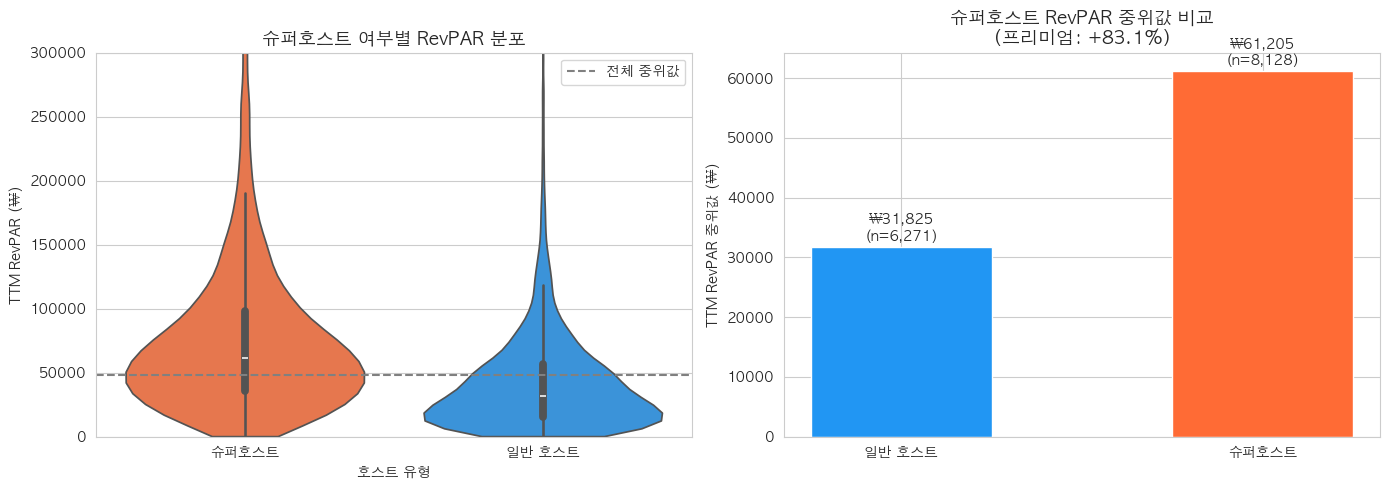

In [2]:
# 슈퍼호스트별 RevPAR 분포
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 바이올린 플롯
superhost_map = {True: '슈퍼호스트', False: '일반 호스트'}
df_ao_plot = df_ao.copy()
df_ao_plot['호스트 유형'] = df_ao_plot['superhost'].map(superhost_map)

sns.violinplot(data=df_ao_plot, x='호스트 유형', y='ttm_revpar',
               palette=['#FF6B35', '#2196F3'], ax=axes[0], cut=0)
axes[0].axhline(KPI_REVPAR_ACTIVE_MEDIAN, color='gray', linestyle='--', label='전체 중위값')
axes[0].set_title('슈퍼호스트 여부별 RevPAR 분포', fontsize=13, fontweight='bold')
axes[0].set_ylabel('TTM RevPAR (₩)')
axes[0].set_ylim(0, 300000)
axes[0].legend()

# 통계 요약 막대
sh_stats = df_ao.groupby('superhost')['ttm_revpar'].agg(['median', 'mean', 'count'])
sh_stats.index = ['일반 호스트', '슈퍼호스트']
bars = axes[1].bar(sh_stats.index, sh_stats['median'],
                    color=['#2196F3', '#FF6B35'], width=0.5)
axes[1].set_title(f'슈퍼호스트 RevPAR 중위값 비교\n(프리미엄: +{KPI_SUPERHOST_PREMIUM*100:.1f}%)',
                   fontsize=13, fontweight='bold')
axes[1].set_ylabel('TTM RevPAR 중위값 (₩)')
for bar, row in zip(bars, sh_stats.itertuples()):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 500,
                 f'₩{row.median:,.0f}\n(n={row.count:,})',
                 ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig(REPORTS_DIR / 'fig_01_superhost_revpar.png', dpi=100, bbox_inches='tight')
plt.show()

## H1 확장: 슈퍼호스트 × 즉시 예약 교차 분석

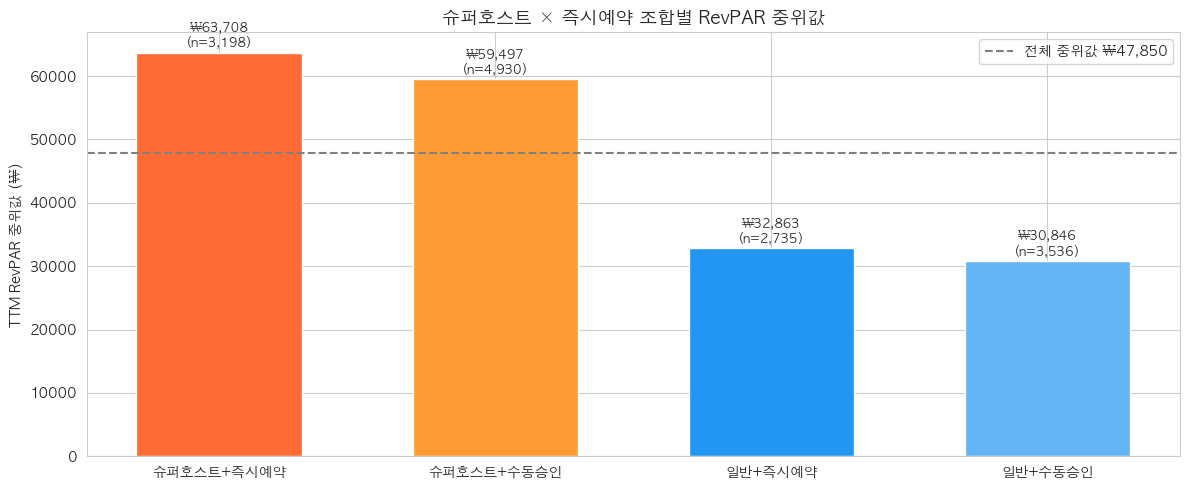

In [3]:
# 교차 분석: 슈퍼호스트 × 즉시 예약
cross_stats = df_ao.groupby(['superhost', 'instant_book'])['ttm_revpar'].agg(
    median='median', count='count'
).reset_index()
cross_stats['그룹'] = cross_stats.apply(
    lambda r: f"{'슈퍼호스트' if r['superhost'] else '일반'}+{'즉시예약' if r['instant_book'] else '수동승인'}", axis=1
)
cross_stats = cross_stats.sort_values('median', ascending=False)

fig, ax = plt.subplots(figsize=(12, 5))
colors = ['#FF6B35', '#FF9B35', '#2196F3', '#64B5F6']
bars = ax.bar(cross_stats['그룹'], cross_stats['median'], color=colors, width=0.6)
ax.axhline(KPI_REVPAR_ACTIVE_MEDIAN, color='gray', linestyle='--', linewidth=1.5,
            label=f'전체 중위값 ₩{KPI_REVPAR_ACTIVE_MEDIAN:,.0f}')
ax.set_title('슈퍼호스트 × 즉시예약 조합별 RevPAR 중위값', fontsize=13, fontweight='bold')
ax.set_ylabel('TTM RevPAR 중위값 (₩)')
for bar, row in zip(bars, cross_stats.itertuples()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 500,
            f'₩{row.median:,.0f}\n(n={row.count:,})', ha='center', va='bottom',
            fontsize=9, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig(REPORTS_DIR / 'fig_01_superhost_instant_cross.png', dpi=100, bbox_inches='tight')
plt.show()

## H2: 숙소 유형(room_type)별 RevPAR 구조

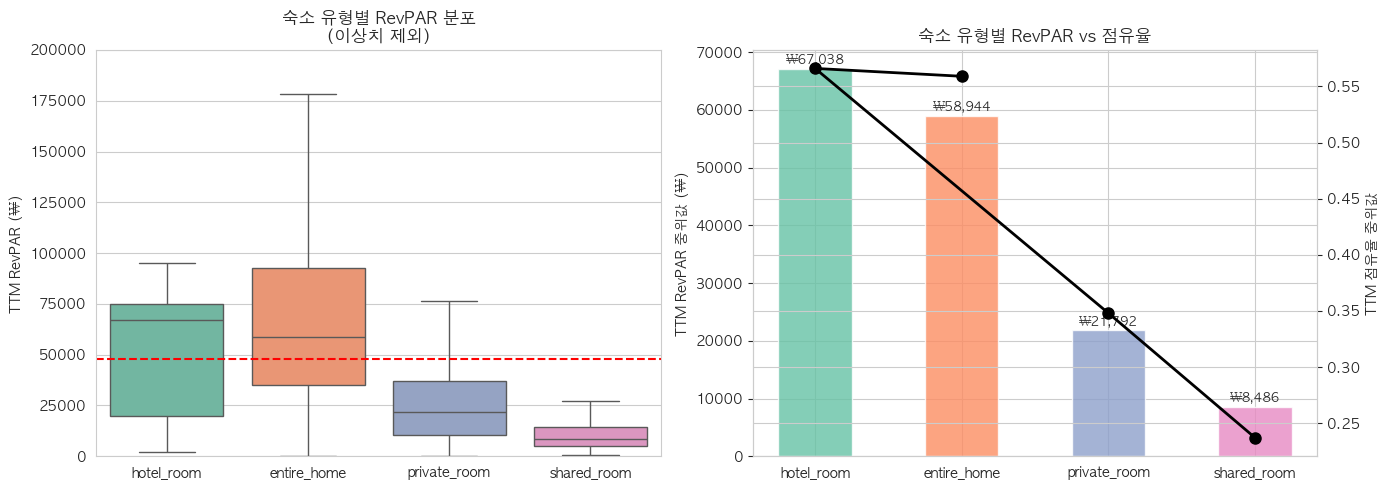


room_type별 통계:
                median          mean  count       q75
room_type                                            
hotel_room    67037.65  52717.200000     32  75134.65
entire_home   58944.00  75137.205880  10800  92606.60
private_room  21791.80  29002.916907   3401  36944.70
shared_room    8486.15  11576.345783    166  14480.30


In [4]:
# room_type별 RevPAR 분포
rt_stats = df_ao.groupby('room_type')['ttm_revpar'].agg(
    median='median', mean='mean', count='count', q75=lambda x: x.quantile(0.75)
).sort_values('median', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 박스플롯
rt_order = rt_stats.index.tolist()
sns.boxplot(data=df_ao, x='room_type', y='ttm_revpar',
            order=rt_order, palette='Set2', ax=axes[0],
            showfliers=False, notch=False)
axes[0].axhline(KPI_REVPAR_ACTIVE_MEDIAN, color='red', linestyle='--')
axes[0].set_title('숙소 유형별 RevPAR 분포\n(이상치 제외)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('TTM RevPAR (₩)')
axes[0].set_xlabel('')
axes[0].set_ylim(0, 200000)

# 중위값 + 점유율 비교
occ_stats = df_ao.groupby('room_type')['ttm_occupancy'].median()
ax2 = axes[1].twinx()
bars = axes[1].bar(rt_stats.index, rt_stats['median'],
                    color=sns.color_palette('Set2', len(rt_stats)), width=0.5, alpha=0.8)
ax2.plot(occ_stats.index, occ_stats.values, 'ko-', markersize=8, linewidth=2, label='중위 점유율')
axes[1].set_title('숙소 유형별 RevPAR vs 점유율', fontsize=12, fontweight='bold')
axes[1].set_ylabel('TTM RevPAR 중위값 (₩)')
ax2.set_ylabel('TTM 점유율 중위값')
for bar, val in zip(bars, rt_stats['median']):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 500,
                 f'₩{val:,.0f}', ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.savefig(REPORTS_DIR / 'fig_01_roomtype_revpar.png', dpi=100, bbox_inches='tight')
plt.show()
print("\nroom_type별 통계:")
print(rt_stats.to_string())

## H3: 사진 수·평점과 RevPAR 관계

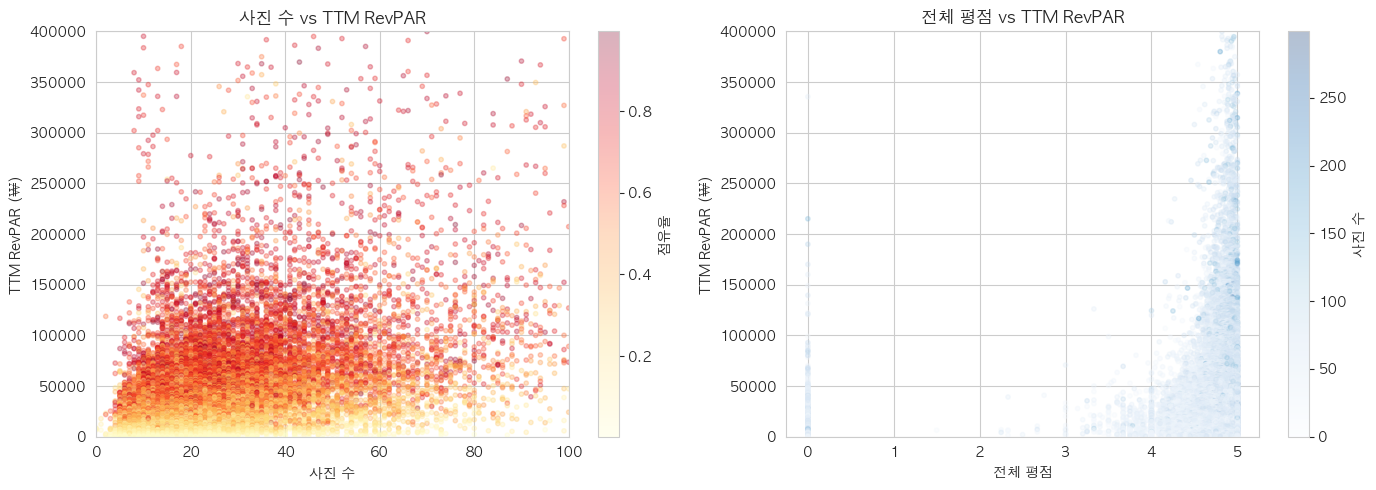

사진 수 Spearman rho=0.395 (p=0.0000)
전체 평점 Spearman rho=0.388 (p=0.0000)


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 사진 수 vs RevPAR
sc1 = axes[0].scatter(df_ao['photos_count'], df_ao['ttm_revpar'],
                       alpha=0.3, s=10, c=df_ao['ttm_occupancy'], cmap='YlOrRd')
axes[0].set_xlim(0, 100)
axes[0].set_ylim(0, 400000)
axes[0].set_title('사진 수 vs TTM RevPAR', fontsize=12, fontweight='bold')
axes[0].set_xlabel('사진 수')
axes[0].set_ylabel('TTM RevPAR (₩)')
plt.colorbar(sc1, ax=axes[0], label='점유율')

# 평점 vs RevPAR
sc2 = axes[1].scatter(df_ao['rating_overall'], df_ao['ttm_revpar'],
                       alpha=0.3, s=10, c=df_ao['photos_count'], cmap='Blues')
axes[1].set_ylim(0, 400000)
axes[1].set_title('전체 평점 vs TTM RevPAR', fontsize=12, fontweight='bold')
axes[1].set_xlabel('전체 평점')
axes[1].set_ylabel('TTM RevPAR (₩)')
plt.colorbar(sc2, ax=axes[1], label='사진 수')

plt.tight_layout()
plt.savefig(REPORTS_DIR / 'fig_01_photos_rating_revpar.png', dpi=100, bbox_inches='tight')
plt.show()

# 상관계수 출력
from scipy.stats import spearmanr
r_photos, p_photos = spearmanr(df_ao['photos_count'].dropna(),
                               df_ao.loc[df_ao['photos_count'].notna(), 'ttm_revpar'])
r_rating, p_rating = spearmanr(df_ao['rating_overall'].dropna(),
                               df_ao.loc[df_ao['rating_overall'].notna(), 'ttm_revpar'])
print(f"사진 수 Spearman rho={r_photos:.3f} (p={p_photos:.4f})")
print(f"전체 평점 Spearman rho={r_rating:.3f} (p={p_rating:.4f})")

## H3 심화: 사진 구간별 RevPAR 분석

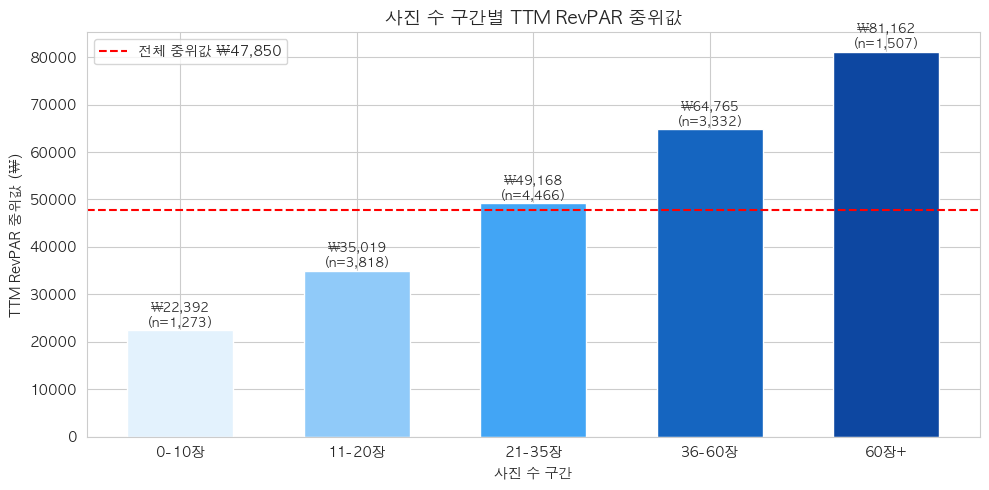

In [6]:
# 사진 수 구간별 분석
df_ao_photos = df_ao.dropna(subset=['photos_count']).copy()
df_ao_photos['사진_구간'] = pd.cut(df_ao_photos['photos_count'],
                                     bins=[0, 10, 20, 35, 60, 500],
                                     labels=['0-10장', '11-20장', '21-35장', '36-60장', '60장+'])

photo_stats = df_ao_photos.groupby('사진_구간', observed=False)['ttm_revpar'].agg(
    median='median', count='count'
)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(photo_stats.index.astype(str), photo_stats['median'],
               color=['#E3F2FD', '#90CAF9', '#42A5F5', '#1565C0', '#0D47A1'], width=0.6)
ax.axhline(KPI_REVPAR_ACTIVE_MEDIAN, color='red', linestyle='--', linewidth=1.5,
            label=f'전체 중위값 ₩{KPI_REVPAR_ACTIVE_MEDIAN:,.0f}')
ax.set_title('사진 수 구간별 TTM RevPAR 중위값', fontsize=13, fontweight='bold')
ax.set_ylabel('TTM RevPAR 중위값 (₩)')
ax.set_xlabel('사진 수 구간')
for bar, row in zip(bars, photo_stats.itertuples()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 300,
            f'₩{row.median:,.0f}\n(n={row.count:,})', ha='center', va='bottom',
            fontsize=9, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig(REPORTS_DIR / 'fig_01_photos_tier_revpar.png', dpi=100, bbox_inches='tight')
plt.show()

## H4: 최소 숙박일 수(min_nights)와 RevPAR 관계

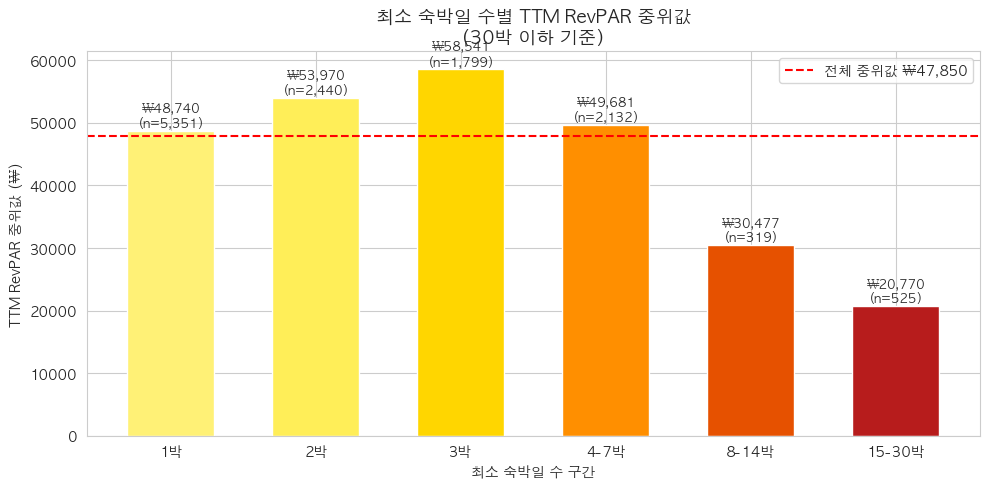

In [7]:
# min_nights 구간별 RevPAR
df_ao_mn = df_ao[df_ao['min_nights'] <= 30].copy()  # 30박 이하만
df_ao_mn['최소박_구간'] = pd.cut(df_ao_mn['min_nights'],
                                   bins=[0, 1, 2, 3, 7, 14, 30],
                                   labels=['1박', '2박', '3박', '4-7박', '8-14박', '15-30박'])

mn_stats = df_ao_mn.groupby('최소박_구간', observed=False)['ttm_revpar'].agg(
    median='median', count='count'
)

fig, ax = plt.subplots(figsize=(10, 5))
colors_mn = ['#FFF176', '#FFEE58', '#FFD600', '#FF8F00', '#E65100', '#B71C1C']
bars = ax.bar(mn_stats.index.astype(str), mn_stats['median'],
               color=colors_mn, width=0.6, edgecolor='white')
ax.axhline(KPI_REVPAR_ACTIVE_MEDIAN, color='red', linestyle='--', linewidth=1.5,
            label=f'전체 중위값 ₩{KPI_REVPAR_ACTIVE_MEDIAN:,.0f}')
ax.set_title('최소 숙박일 수별 TTM RevPAR 중위값\n(30박 이하 기준)', fontsize=13, fontweight='bold')
ax.set_ylabel('TTM RevPAR 중위값 (₩)')
ax.set_xlabel('최소 숙박일 수 구간')
for bar, row in zip(bars, mn_stats.itertuples()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 300,
            f'₩{row.median:,.0f}\n(n={row.count:,})', ha='center', va='bottom', fontsize=9)
ax.legend()
plt.tight_layout()
plt.savefig(REPORTS_DIR / 'fig_01_minnights_revpar.png', dpi=100, bbox_inches='tight')
plt.show()

## H5: 추가 요금 정책과 RevPAR

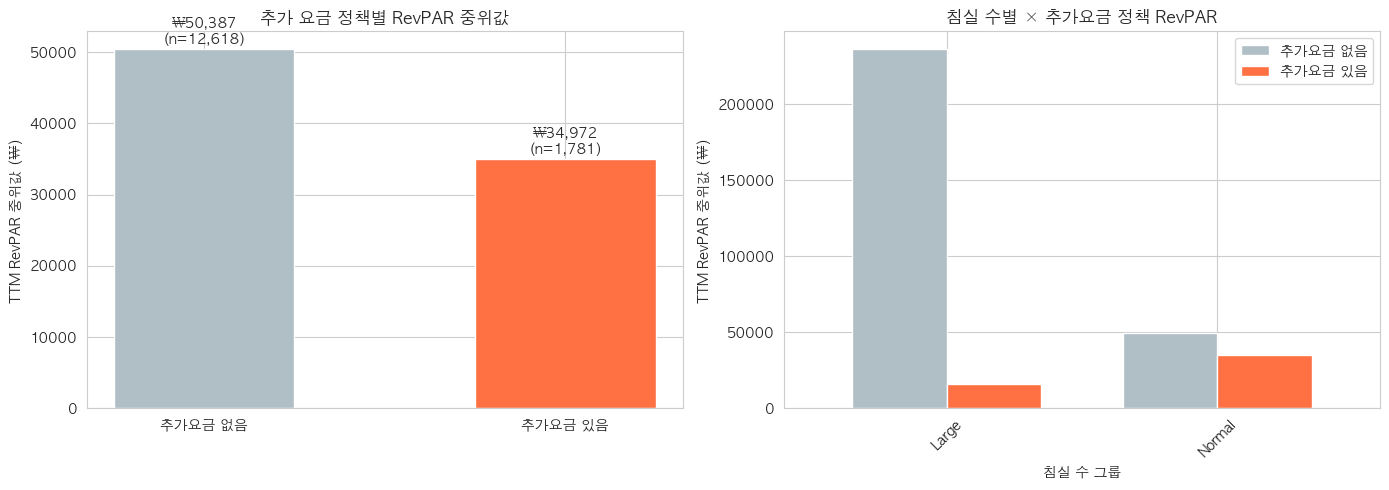

In [8]:
# extra_guest_fee_policy별 분석 (숙소 크기 구간 교차)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 전체 비교
efp_stats = df_ao.groupby('extra_guest_fee_policy')['ttm_revpar'].agg(
    median='median', count='count'
)
labels = {0: '추가요금 없음', 1: '추가요금 있음'}
efp_stats.index = [labels[i] for i in efp_stats.index]
bars = axes[0].bar(efp_stats.index, efp_stats['median'],
                    color=['#B0BEC5', '#FF7043'], width=0.5)
axes[0].set_title('추가 요금 정책별 RevPAR 중위값', fontsize=12, fontweight='bold')
axes[0].set_ylabel('TTM RevPAR 중위값 (₩)')
for bar, row in zip(bars, efp_stats.itertuples()):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 300,
                 f'₩{row.median:,.0f}\n(n={row.count:,})', ha='center', va='bottom',
                 fontweight='bold')

# 침실 수별 추가요금 교차
bgrp_efp = df_ao.groupby(['bedrooms_group', 'extra_guest_fee_policy'])['ttm_revpar'].median().unstack()
bgrp_efp.columns = ['추가요금 없음', '추가요금 있음']
bgrp_efp = bgrp_efp.dropna()
bgrp_efp.plot(kind='bar', ax=axes[1], color=['#B0BEC5', '#FF7043'], width=0.7, edgecolor='white')
axes[1].set_title('침실 수별 × 추가요금 정책 RevPAR', fontsize=12, fontweight='bold')
axes[1].set_ylabel('TTM RevPAR 중위값 (₩)')
axes[1].set_xlabel('침실 수 그룹')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend()

plt.tight_layout()
plt.savefig(REPORTS_DIR / 'fig_01_extrafee_revpar.png', dpi=100, bbox_inches='tight')
plt.show()

## 6️⃣ 위치: POI 거리 효과

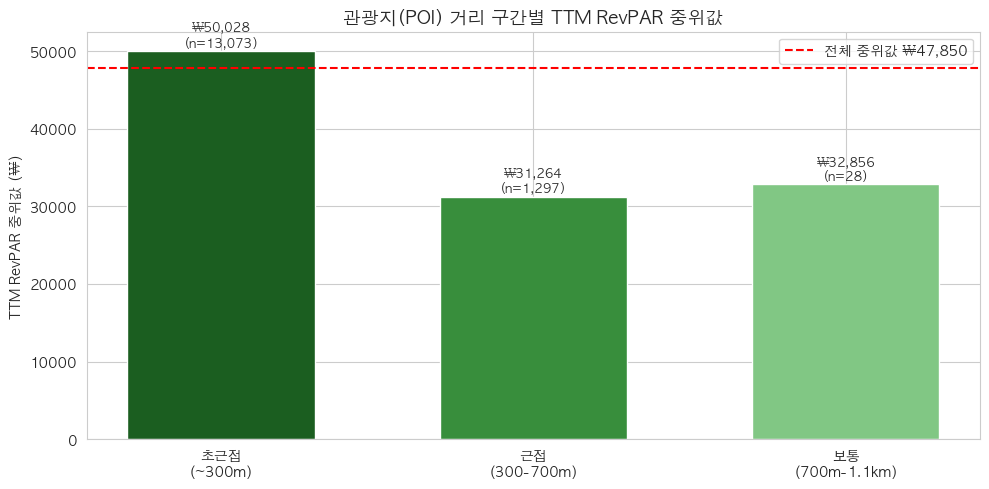

In [9]:
# POI 거리 구간별 RevPAR
df_ao_poi = df_ao.dropna(subset=['nearest_poi_dist_km']).copy()
df_ao_poi['POI_거리_구간'] = pd.cut(df_ao_poi['nearest_poi_dist_km'],
                                     bins=[0, 0.3, 0.7, 1.1, 2.0],
                                     labels=['초근접\n(~300m)', '근접\n(300-700m)',
                                             '보통\n(700m-1.1km)', '원거리\n(1.1km+)'])

poi_stats = df_ao_poi.groupby('POI_거리_구간', observed=False)['ttm_revpar'].agg(
    median='median', count='count'
)

fig, ax = plt.subplots(figsize=(10, 5))
colors_poi = ['#1B5E20', '#388E3C', '#81C784', '#C8E6C9']
bars = ax.bar(poi_stats.index.astype(str), poi_stats['median'],
               color=colors_poi, width=0.6)
ax.axhline(KPI_REVPAR_ACTIVE_MEDIAN, color='red', linestyle='--',
            label=f'전체 중위값 ₩{KPI_REVPAR_ACTIVE_MEDIAN:,.0f}')
ax.set_title('관광지(POI) 거리 구간별 TTM RevPAR 중위값', fontsize=13, fontweight='bold')
ax.set_ylabel('TTM RevPAR 중위값 (₩)')
for bar, row in zip(bars, poi_stats.itertuples()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 300,
            f'₩{row.median:,.0f}\n(n={row.count:,})', ha='center', va='bottom', fontsize=9)
ax.legend()
plt.tight_layout()
plt.savefig(REPORTS_DIR / 'fig_01_poi_dist_revpar.png', dpi=100, bbox_inches='tight')
plt.show()

## 📋 호스트 EDA 요약

**핵심 발견사항:**
1. **슈퍼호스트 효과 강력** — 중위 RevPAR +83.1%, 슈퍼호스트+즉시예약 조합이 최적
2. **entire_home 압도적 우위** — private_room의 약 2-3배 RevPAR
3. **사진 20-35장 최적 구간** — 그 이상은 한계 효과 감소
4. **min_nights 2-3박 최적** — 1박과 7박+ 모두 RevPAR 하락
5. **추가 요금 정책 활성화가 유리** — 특히 2+ 침실 대형 숙소에서 효과 뚜렷
6. **POI 거리 최근접이 유리하나 차이 미미** — 유형(tourist/transport)이 더 중요할 가능성

**다음 단계:** `02_host_preprocessing.ipynb`에서 모델 입력 피처 준비

In [10]:
# EDA 주요 통계 저장
import json

eda_summary = {
    "superhost_premium_pct": round(KPI_SUPERHOST_PREMIUM * 100, 1),
    "superhost_revpar_median": int(df_ao[df_ao['superhost']==True]['ttm_revpar'].median()),
    "non_superhost_revpar_median": int(df_ao[df_ao['superhost']==False]['ttm_revpar'].median()),
    "entire_home_revpar_median": int(df_ao[df_ao['room_type']=='entire_home']['ttm_revpar'].median()),
    "private_room_revpar_median": int(df_ao[df_ao['room_type']=='private_room']['ttm_revpar'].median()),
    "optimal_photos_range": "21-35장",
    "optimal_min_nights": "2-3박"
}

with open(REPORTS_DIR / 'host_eda_summary.json', 'w', encoding='utf-8') as f:
    json.dump(eda_summary, f, ensure_ascii=False, indent=2)
print("✅ EDA 요약 저장: reports/host_eda_summary.json")
print(json.dumps(eda_summary, ensure_ascii=False, indent=2))

✅ EDA 요약 저장: reports/host_eda_summary.json
{
  "superhost_premium_pct": 83.1,
  "superhost_revpar_median": 61205,
  "non_superhost_revpar_median": 31825,
  "entire_home_revpar_median": 58944,
  "private_room_revpar_median": 21791,
  "optimal_photos_range": "21-35장",
  "optimal_min_nights": "2-3박"
}
